<a href="https://colab.research.google.com/github/JuanitaRozo/Transformers/blob/main/Implementaci%C3%B3n_de_un_Transformer_b%C3%A1sico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Dense,
    LayerNormalization,
    MultiHeadAttention,
    Dropout,
    GlobalAveragePooling1D
)

from tensorflow.keras.models import Model
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("TensorFlow:", tf.__version__)
print("Entorno preparado correctamente")


TensorFlow: 2.21.0
Entorno preparado correctamente


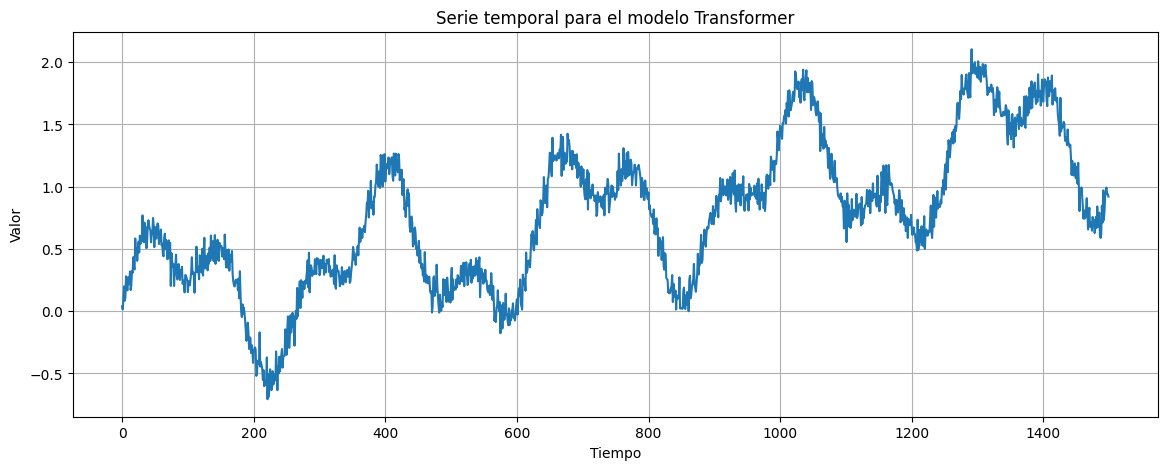

In [ ]:
np.random.seed(42)

tiempo = np.arange(0, 1500)

serie = (
    0.5 * np.sin(0.02 * tiempo) +
    0.3 * np.sin(0.05 * tiempo) +
    0.001 * tiempo +
    np.random.normal(0, 0.08, len(tiempo))
)

datos = pd.DataFrame({
    "Tiempo": tiempo,
    "Valor": serie
})

plt.figure(figsize=(14, 5))
plt.plot(datos["Tiempo"], datos["Valor"])

plt.title("Serie temporal para el modelo Transformer")
plt.xlabel("Tiempo")
plt.ylabel("Valor")
plt.grid(True)

plt.show()


In [ ]:

scaler = MinMaxScaler(feature_range=(0, 1))

datos_normalizados = scaler.fit_transform(
    datos[["Valor"]]
)

VENTANA = 30

def crear_secuencias(datos, ventana):
    X, y = [], []

    for i in range(len(datos) - ventana):
        X.append(datos[i:i + ventana])
        y.append(datos[i + ventana])

    return np.array(X), np.array(y)


X, y = crear_secuencias(datos_normalizados, VENTANA)

limite = int(len(X) * 0.80)

X_train = X[:limite]
X_test = X[limite:]

y_train = y[:limite]
y_test = y[limite:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (1176, 30, 1)
X_test: (294, 30, 1)
y_train: (1176, 1)
y_test: (294, 1)


In [ ]:

def codificacion_posicional(longitud, dimension):

    posicion = np.arange(longitud)[:, np.newaxis]

    dimensiones = np.arange(dimension)[np.newaxis, :]

    angulos = posicion / np.power(
        10000,
        (2 * (dimensiones // 2)) / dimension
    )

    codificacion = np.zeros(
        (longitud, dimension)
    )

    codificacion[:, 0::2] = np.sin(
        angulos[:, 0::2]
    )

    codificacion[:, 1::2] = np.cos(
        angulos[:, 1::2]
    )

    return tf.constant(
        codificacion,
        dtype=tf.float32
    )


posiciones = codificacion_posicional(VENTANA, 64)

print("Dimensiones de la codificación:", posiciones.shape)


Dimensiones de la codificación: (30, 64)


In [ ]:

def bloque_transformer(
    entradas,
    dimension=64,
    cabezas=4,
    dimension_ff=128,
    dropout=0.1
):

    atencion = MultiHeadAttention(
        num_heads=cabezas,
        key_dim=dimension // cabezas
    )(entradas, entradas)

    atencion = Dropout(dropout)(atencion)

    salida1 = LayerNormalization(
        epsilon=1e-6
    )(entradas + atencion)

    red_densa = Dense(
        dimension_ff,
        activation="relu"
    )(salida1)

    red_densa = Dense(dimension)(red_densa)

    red_densa = Dropout(dropout)(red_densa)

    salida2 = LayerNormalization(
        epsilon=1e-6
    )(salida1 + red_densa)

    return salida2


In [ ]:

dimension = 64

entrada = Input(shape=(VENTANA, 1))

# Proyección de los datos a un espacio de 64 dimensiones
x = Dense(dimension)(entrada)

# Codificación posicional
posiciones = codificacion_posicional(
    VENTANA,
    dimension
)

x = x + posiciones

# Bloque Transformer
x = bloque_transformer(
    x,
    dimension=dimension,
    cabezas=4,
    dimension_ff=128,
    dropout=0.1
)

# Representación global de la secuencia
x = GlobalAveragePooling1D()(x)

# Capas de predicción
x = Dense(32, activation="relu")(x)

salida = Dense(1)(x)

modelo_transformer = Model(
    inputs=entrada,
    outputs=salida
)

modelo_transformer.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

modelo_transformer.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 30, 64)    │        128 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 30, 64)    │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 64)    │     16,640 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 30, 64)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 30, 64)    │          0 │ add[0][0],        │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 30, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 30, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 30, 64)    │      8,256 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 30, 64)    │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 30, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 64)    │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      2,080 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 1)         │         33 │ dense_3[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 35,713 (139.50 KB)

 Trainable params: 35,713 (139.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

historial_transformer = modelo_transformer.fit(
    X_train,
    y_train,
    epochs=40,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    verbose=1
)


Epoch 1/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - loss: 0.0572 - mae: 0.2007 - val_loss: 0.1237 - val_mae: 0.3310
Epoch 2/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0596 - mae: 0.2050 - val_loss: 0.0109 - val_mae: 0.0801
Epoch 3/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0308 - mae: 0.1511 - val_loss: 0.0090 - val_mae: 0.0733
Epoch 4/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 0.0231 - mae: 0.1283 - val_loss: 0.0090 - val_mae: 0.0725
Epoch 5/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0189 - mae: 0.1127 - val_loss: 0.0107 - val_mae: 0.0785
Epoch 6/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - loss: 0.0170 - mae: 0.1060 - val_loss: 0.0117 - val_mae: 0.0828
Epoch 7/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.0154 - mae: 0.1002 - val_loss: 0.0116 - val_mae: 0.0832
Epoch 8/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0138 - mae: 0.0945 - val_loss: 0.0103 - val_mae: 0.0784
Epoch 9/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.012

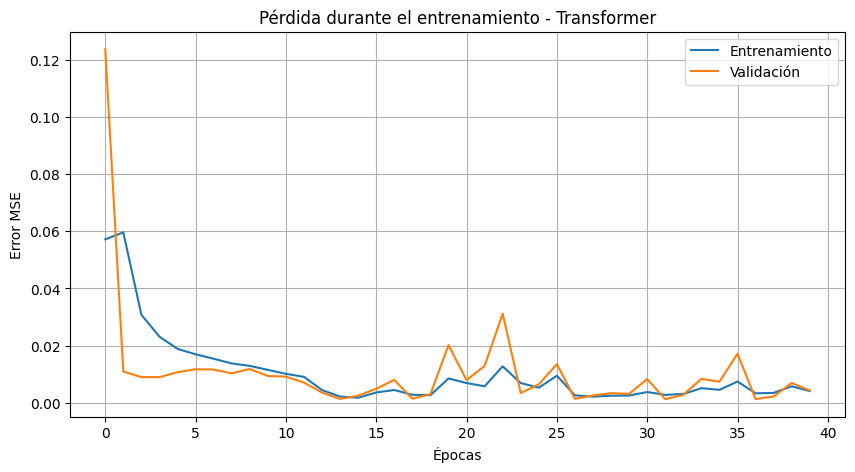

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    historial_transformer.history["loss"],
    label="Entrenamiento"
)

plt.plot(
    historial_transformer.history["val_loss"],
    label="Validación"
)

plt.title("Pérdida durante el entrenamiento - Transformer")
plt.xlabel("Épocas")
plt.ylabel("Error MSE")

plt.legend()
plt.grid(True)

plt.show()


In [ ]:

perdida, mae = modelo_transformer.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Error MSE:", perdida)
print("Error MAE:", mae)


Error MSE: 0.0029987390153110027
Error MAE: 0.04462936148047447


In [ ]:

predicciones = modelo_transformer.predict(X_test)

predicciones_reales = scaler.inverse_transform(
    predicciones
)

valores_reales = scaler.inverse_transform(
    y_test
)

mse = mean_squared_error(
    valores_reales,
    predicciones_reales
)

mae_real = mean_absolute_error(
    valores_reales,
    predicciones_reales
)

print("Error cuadrático medio (MSE):", mse)
print("Error absoluto medio (MAE):", mae_real)


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Error cuadrático medio (MSE): 0.023697143324392652
Error absoluto medio (MAE): 0.12545827674264193


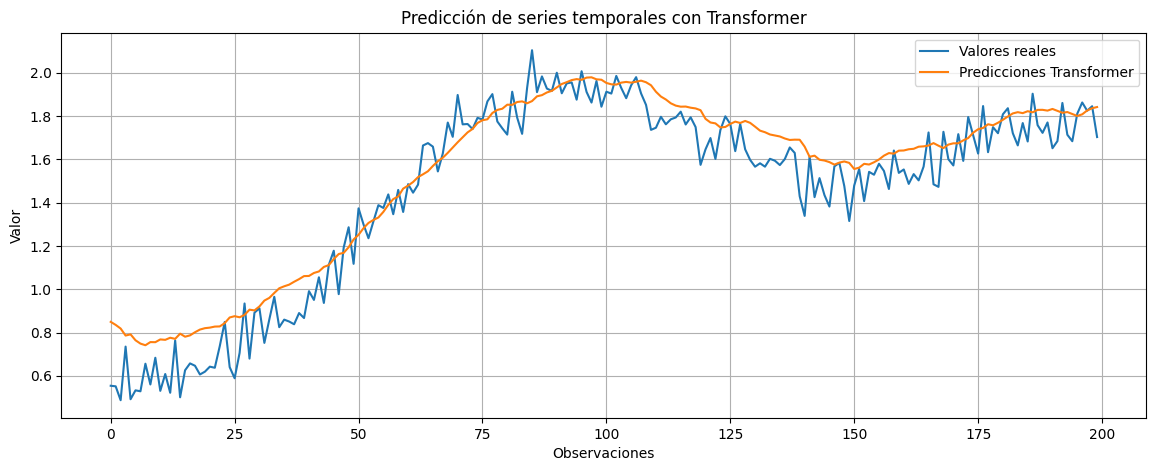

In [ ]:

plt.figure(figsize=(14, 5))

plt.plot(
    valores_reales[:200],
    label="Valores reales"
)

plt.plot(
    predicciones_reales[:200],
    label="Predicciones Transformer"
)

plt.title("Predicción de series temporales con Transformer")
plt.xlabel("Observaciones")
plt.ylabel("Valor")

plt.legend()
plt.grid(True)

plt.show()


In [ ]:

modelo_transformer.save("modelo_transformer.keras")

print("Modelo Transformer guardado correctamente")


Modelo Transformer guardado correctamente
